In [305]:
load("visualize.sage")
load("surfaces.sage")
load("curves.sage")

R.<x0,x1,x2> = QQ['x0,x1,x2']

F = general_curve(3)
plot_curve(F)

In [306]:
R1.<x0,x1,x2,u0,u1,u2> = QQ['x0,x1,x2,u0,u1,u2']

G = dual_curve(F,R1)
plot_curve(G)

[]
[]
[]


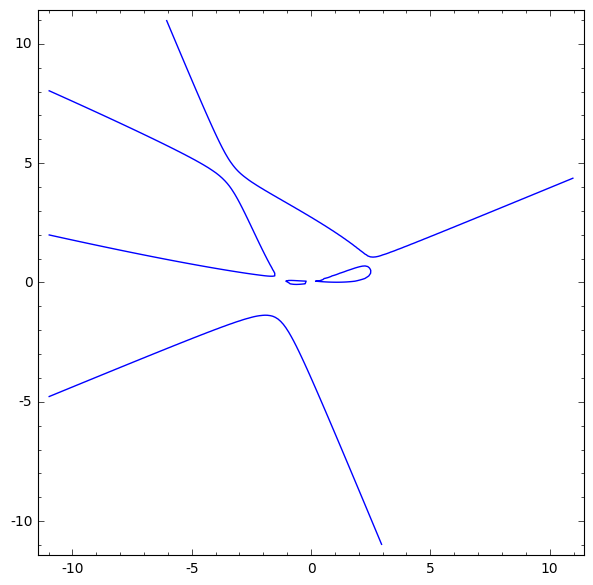

In [15]:
load("visualize.sage")
load("surfaces.sage")

R.<x0,x1,x2> = QQ['x0,x1,x2']
X = matrix(R,[[x0],[x1],[x2]])

## Define F
M0 = random_matrix(ZZ,1,3)
M1 = random_matrix(ZZ,1,3)
M2 = random_matrix(ZZ,1,3)
M3 = random_matrix(ZZ,1,3)
N1 = random_matrix(ZZ,3,3)
N2 = random_matrix(ZZ,3,3)

F = (M0*X)[0,0]*x0*x1*x2+(
(X.transpose()*N1*X)[0,0]*(X.transpose()*N2*X)[0,0])
C=ideal(F)

J=jacobian(F,(x0,x1,x2))
SingularLocus=S+ideal(J.list())
print(SingularLocus.subs(x0=1).primary_decomposition())
print(SingularLocus.subs(x1=1).primary_decomposition())
print(SingularLocus.subs(x2=1).primary_decomposition())

Curve = C.subs(x0=1).change_ring(QQ['x1,x2'])

s = singular.eval
s('LIB "surf.lib";')
s("ring r = 0,(x1,x2),dp;")
s("plot("+str(Curve.gens()[0])+")")

Curve.plot()

We consider a surface $S$ in $\mathbb P^3$ defined by a polynomial $F \in \mathbb R[x_0,x_1,x_2,x_3]$.

In [204]:
load("visualize.sage")
load("surfaces.sage")

R.<x0,x1,x2,x3> = QQ['x0,x1,x2,x3']
X = matrix(R,[[x0],[x1],[x2],[x3]])

## Define F
M0 = random_matrix(ZZ,1,4)
M1 = random_matrix(ZZ,1,4)
M2 = random_matrix(ZZ,1,4)
M3 = random_matrix(ZZ,1,4)
N1 = random_matrix(ZZ,4,4)
N2 = random_matrix(ZZ,4,4)

#F = (M0*X)[0,0]*x0*x1*x2+(M1*X)[0,0]*x0*x1*x3+(M2*X)[0,0]*x0*x2*x3+(M3*X)[0,0]*x1*x2*x3+(
#(X.transpose()*N1*X)[0,0]*(X.transpose()*N2*X)[0,0])
F = (X.transpose()*N1*X)[0,0]*x0+x2*x3^2+x2^3

F = general_surface(2)
S=ideal(F)
F

-x0^3 + x0^2*x1 + 2*x0^2*x2 - x0*x1*x2 - 4*x0^2*x3 + 2*x0*x2*x3 - x1*x2*x3

In [62]:
plotSurf(F)

Let's verify that $S$ is smooth:

In [28]:
J=jacobian(F,(x0,x1,x2,x3))
SingularLocus=S+ideal(J.list())
print(SingularLocus.subs(x0=1).primary_decomposition())
print(SingularLocus.subs(x1=1).primary_decomposition())
print(SingularLocus.subs(x2=1).primary_decomposition())
print(SingularLocus.subs(x3=1).primary_decomposition())

[]
[]
[]
[]


We can also look at the dual $S^\vee$ in $(\mathbb P^3)^*$.

In [205]:
R1.<x0,x1,x2,x3,u0,u1,u2,u3> = QQ['x0,x1,x2,x3,u0,u1,u2,u3']
Dual = dual_surface(S, R1)
Dual

Ideal (0) of Multivariate Polynomial Ring in x0, x1, x2, x3, u0, u1, u2, u3 over Rational Field

We consider the outline of $S$ from a viewpoint $c$.

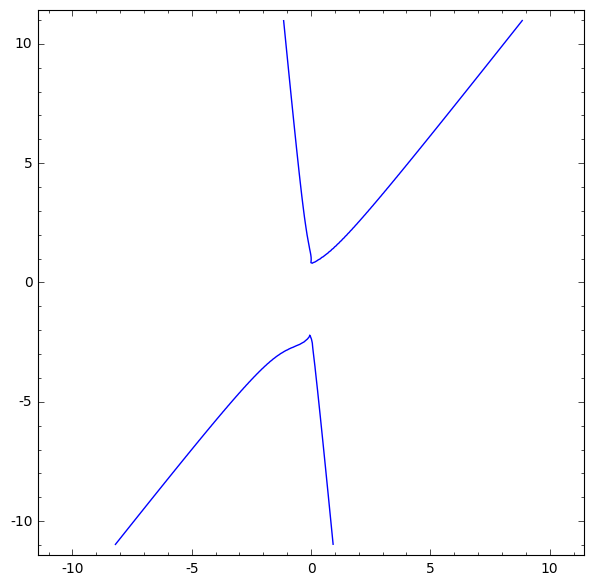

In [29]:
R2.<x0,x1,x2,x3,u0,u1,u2> = QQ['x0,x1,x2,x3,u0,u1,u2']

P = vector([1,0,0,0])
ProjMatrix = matrix([[-P[1],P[0],0,0],[-P[2],0,P[0],0],[-P[3],0,0,P[0]]])
ProjMatrix

X = matrix(R2, [[x0], [x1], [x2], [x3]])
U = matrix(R2, [[u0],[u1],[u2]])
S = S.change_ring(R2)

IncidenceIdeal = S + ideal((ProjMatrix*X).augment(U).minors(2))
IncidenceIdeal = S + ideal((ProjMatrix*X-U).list())

Ramification = IncidenceIdeal + ideal(jacobian(IncidenceIdeal.gens(),(x0,x1,x2,x3)).minors(4))

Outline = Ramification.saturation(ideal(x0, x1, x2, x3))[0]
Outline = Outline.elimination_ideal((x0, x1, x2, x3))

Outline = Outline.subs(u0=1).change_ring(QQ['u1,u2'])

s = singular.eval
s('LIB "surf.lib";')
s("ring r = 0,(u1,u2),dp;")
s("plot("+str(Outline.gens()[0])+")")

Outline.plot()

# Outline


We now consider a *variable* viewpoint $c$.

In [ ]:
R3.<x0,x1,x2,x3,u0,u1,u2,c0,c1,c2,c3> = QQ['x0,x1,x2,x3,u0,u1,u2,c0,c1,c2,c3']

P = vector([c0,c1,c2,c3])
ProjMatrix = matrix([[-P[1],P[0],0,0],[-P[2],0,P[0],0],[-P[3],0,0,P[0]]])
ProjMatrix

X = matrix(R3, [[x0], [x1], [x2], [x3]])
U = matrix(R3, [[u0],[u1],[u2]])
S = S.change_ring(R3)

IncidenceIdeal = S + ideal((ProjMatrix*X).augment(U).minors(2))
IncidenceIdeal = S + ideal((ProjMatrix*X-U).list())

Ramification = IncidenceIdeal + ideal(jacobian(IncidenceIdeal.gens(),(x0,x1,x2,x3)).minors(4))

Outline = Ramification.saturation(ideal(x0, x1, x2, x3))[0]
Outline = Outline.elimination_ideal((x0, x1, x2, x3))

#Outline.primary_decomposition()

KeyboardInterrupt: 

In [97]:
s = singular.eval
s('LIB "surf.lib";')
s("ring r = 0,(x,y),dp;")
s("plot(x^2-y^3)")

'Close window to exit from `singularsurf`.'